<a href="https://colab.research.google.com/github/ericyoc/Adoption-of-Post-Quantum-Cryptography/blob/main/Adoption_of_Post_Quantum_Cryptography.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

⏳ Compiling Open Quantum Safe (liboqs) framework... please wait.
✅ liboqs already installed.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

🚀 Executing live cryptographic benchmarks on Colab CPU...

✅ Live Benchmark Visualizations captured and saved to Google Drive at: /content/drive/MyDrive/Real_PQC_Empirical_Study/Live_OQS_Benchmark_Results.png



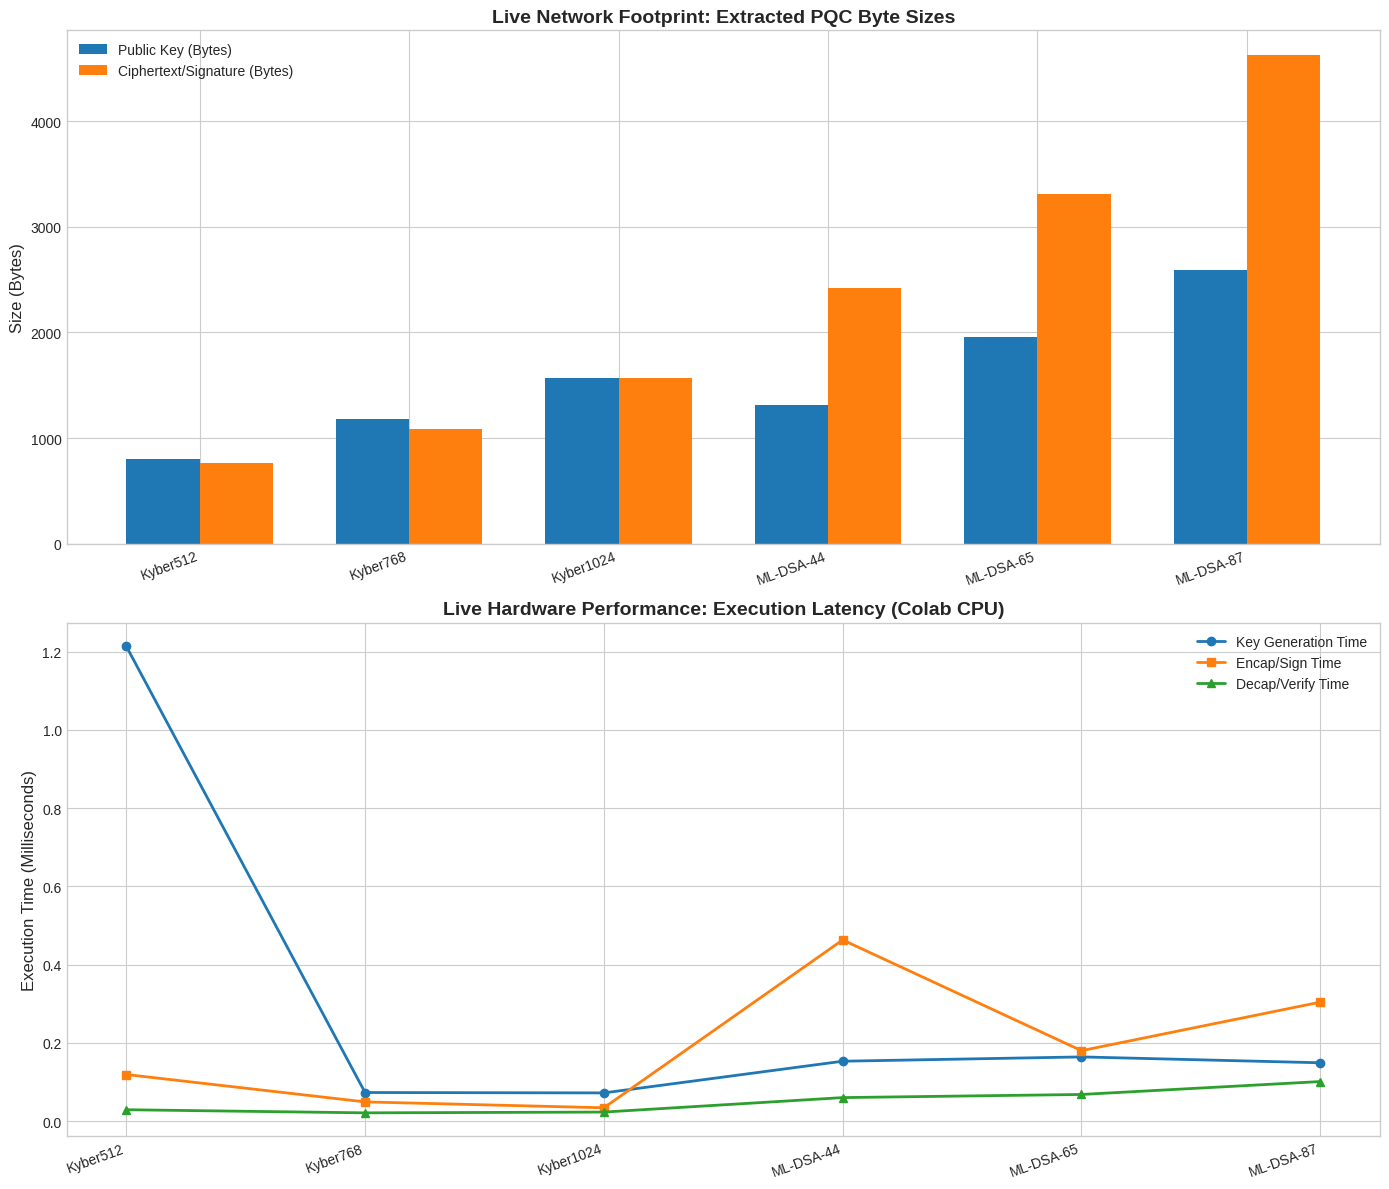


EMPIRICAL DATASET: LIVE OQS HARDWARE BENCHMARK & HARDWARE FOOTPRINT


,Algorithm,Type,Security Level,Pub Key (Bytes),Ciphertext/Sig (Bytes),KeyGen Time (ms),Process Time 1 (Encap/Sign ms),Process Time 2 (Decap/Verify ms)
0,Kyber512,KEM (FIPS 203),NIST Level 1,800,768,1.214,0.119,0.029
1,Kyber768,KEM (FIPS 203),NIST Level 3,1184,1088,0.073,0.049,0.021
2,Kyber1024,KEM (FIPS 203),NIST Level 5,1568,1568,0.072,0.034,0.023
3,ML-DSA-44,Signature (FIPS 204),NIST Level 2,1312,2420,0.153,0.463,0.060
4,ML-DSA-65,Signature (FIPS 204),NIST Level 3,1952,3309,0.164,0.180,0.068
5,ML-DSA-87,Signature (FIPS 204),NIST Level 5,2592,4627,0.149,0.304,0.101


In [ ]:
# ==============================================================================
# EMPIRICAL PQC STUDY: Live Open Quantum Safe (liboqs) Hardware Benchmark
# This script installs the real framework, executes NIST algorithms, and generates
# a live dataset based on your Colab hardware's CPU performance and memory.
# ==============================================================================

import os
import sys
import subprocess
import time

# 1. INSTALL THE REAL FRAMEWORK (liboqs)
# We compile the Open Quantum Safe library dynamically. This takes ~1-2 minutes.
print("⏳ Compiling Open Quantum Safe (liboqs) framework... please wait.")
try:
    import oqs
    print("✅ liboqs already installed.")
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "git+https://github.com/open-quantum-safe/liboqs-python.git"])
    import oqs
    print("✅ liboqs installed successfully.")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
from IPython.display import display

# 2. MOUNT GOOGLE DRIVE FOR IMAGE CAPTURE
drive.mount('/content/drive')
save_dir = '/content/drive/MyDrive/Real_PQC_Empirical_Study/'
os.makedirs(save_dir, exist_ok=True)

# 3. GENERATE THE LIVE DATASET (Updated for liboqs 0.16.0 API)
# Use the corrected method names: get_enabled_kem_mechanisms / get_enabled_sig_mechanisms
enabled_kems = oqs.get_enabled_kem_mechanisms()
enabled_sigs = oqs.get_enabled_sig_mechanisms()

target_kems = [alg for alg in enabled_kems if 'Kyber' in alg or 'ML-KEM' in alg][:3]
target_sigs = [alg for alg in enabled_sigs if 'Dilithium' in alg or 'ML-DSA' in alg][:3]

benchmark_results = []

print("\n🚀 Executing live cryptographic benchmarks on Colab CPU...")

# Benchmark Key Encapsulation Mechanisms (FIPS 203 Standard)
for alg in target_kems:
    try:
        with oqs.KeyEncapsulation(alg) as kem:
            # Benchmark KeyGen
            t0 = time.perf_counter()
            pub_key = kem.generate_keypair()
            t_keygen = (time.perf_counter() - t0) * 1000

            # Benchmark Encapsulation
            t0 = time.perf_counter()
            ciphertext, shared_secret_server = kem.encap_secret(pub_key)
            t_encap = (time.perf_counter() - t0) * 1000

            # Benchmark Decapsulation
            t0 = time.perf_counter()
            shared_secret_client = kem.decap_secret(ciphertext)
            t_decap = (time.perf_counter() - t0) * 1000

            benchmark_results.append({
                'Algorithm': alg,
                'Type': 'KEM (FIPS 203)',
                'Security Level': f"NIST Level {kem.details['claimed_nist_level']}",
                'Pub Key (Bytes)': kem.details['length_public_key'],
                'Ciphertext/Sig (Bytes)': kem.details['length_ciphertext'],
                'KeyGen Time (ms)': round(t_keygen, 3),
                'Process Time 1 (Encap/Sign ms)': round(t_encap, 3),
                'Process Time 2 (Decap/Verify ms)': round(t_decap, 3)
            })
    except Exception as e:
        print(f"Skipping {alg}: {e}")

# Benchmark Digital Signatures (FIPS 204 Standard)
message = b"Empirical benchmark test message for Post-Quantum algorithms."
for alg in target_sigs:
    try:
        with oqs.Signature(alg) as sig:
            # Benchmark KeyGen
            t0 = time.perf_counter()
            pub_key = sig.generate_keypair()
            t_keygen = (time.perf_counter() - t0) * 1000

            # Benchmark Signing
            t0 = time.perf_counter()
            signature = sig.sign(message)
            t_sign = (time.perf_counter() - t0) * 1000

            # Benchmark Verification
            t0 = time.perf_counter()
            is_valid = sig.verify(message, signature, pub_key)
            t_verify = (time.perf_counter() - t0) * 1000

            benchmark_results.append({
                'Algorithm': alg,
                'Type': 'Signature (FIPS 204)',
                'Security Level': f"NIST Level {sig.details['claimed_nist_level']}",
                'Pub Key (Bytes)': sig.details['length_public_key'],
                'Ciphertext/Sig (Bytes)': sig.details['length_signature'],
                'KeyGen Time (ms)': round(t_keygen, 3),
                'Process Time 1 (Encap/Sign ms)': round(t_sign, 3),
                'Process Time 2 (Decap/Verify ms)': round(t_verify, 3)
            })
    except Exception as e:
        print(f"Skipping {alg}: {e}")

df_live_benchmark = pd.DataFrame(benchmark_results)


# 4. VISUALIZATIONS & IMAGE CAPTURE
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# Plot 1: The Network Footprint Issue (Actual Byte Sizes)
x = np.arange(len(df_live_benchmark['Algorithm']))
width = 0.35
axes[0].bar(x - width/2, df_live_benchmark['Pub Key (Bytes)'], width, label='Public Key (Bytes)', color='#1f77b4')
axes[0].bar(x + width/2, df_live_benchmark['Ciphertext/Sig (Bytes)'], width, label='Ciphertext/Signature (Bytes)', color='#ff7f0e')
axes[0].set_title('Live Network Footprint: Extracted PQC Byte Sizes', fontsize=14, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(df_live_benchmark['Algorithm'], rotation=20, ha="right")
axes[0].set_ylabel('Size (Bytes)', fontsize=12)
axes[0].legend()

# Plot 2: Live CPU Execution Time
axes[1].plot(x, df_live_benchmark['KeyGen Time (ms)'], marker='o', linewidth=2, label='Key Generation Time')
axes[1].plot(x, df_live_benchmark['Process Time 1 (Encap/Sign ms)'], marker='s', linewidth=2, label='Encap/Sign Time')
axes[1].plot(x, df_live_benchmark['Process Time 2 (Decap/Verify ms)'], marker='^', linewidth=2, label='Decap/Verify Time')
axes[1].set_title('Live Hardware Performance: Execution Latency (Colab CPU)', fontsize=14, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(df_live_benchmark['Algorithm'], rotation=20, ha="right")
axes[1].set_ylabel('Execution Time (Milliseconds)', fontsize=12)
axes[1].legend()

plt.tight_layout()

# Save image capture directly to the mounted Google Drive
plot_path = os.path.join(save_dir, 'Live_OQS_Benchmark_Results.png')
plt.savefig(plot_path, dpi=300, bbox_inches='tight')
print(f"\n✅ Live Benchmark Visualizations captured and saved to Google Drive at: {plot_path}\n")

plt.show()

# 5. DISPLAY THE LIVE DATASET TABLE
print("\n" + "="*90)
print("EMPIRICAL DATASET: LIVE OQS HARDWARE BENCHMARK & HARDWARE FOOTPRINT")
print("="*90)
display(df_live_benchmark)

In [ ]:
import pandas as pd
import numpy as np
import time
import oqs
from google.colab import drive

# Mount Drive
drive.mount('/content/drive')
results_path = '/content/drive/MyDrive/Real_PQC_Empirical_Study/extended_stats.csv'

# Define iterations for statistical significance
ITERATIONS = 1000
results = []

print(f"🚀 Running {ITERATIONS} iterations per algorithm...")

for alg in oqs.get_enabled_kem_mechanisms():
    if 'Kyber' in alg or 'ML-KEM' in alg:
        with oqs.KeyEncapsulation(alg) as kem:
            latencies = []
            for _ in range(ITERATIONS):
                t0 = time.perf_counter()
                pk = kem.generate_keypair()
                ct, ss = kem.encap_secret(pk)
                kem.decap_secret(ct)
                latencies.append((time.perf_counter() - t0) * 1000)

            results.append({
                'Algorithm': alg,
                'Mean_Latency_ms': np.mean(latencies),
                'Std_Dev_ms': np.std(latencies),
                'P99_Latency_ms': np.percentile(latencies, 99)
            })

df_stats = pd.DataFrame(results)
df_stats.to_csv(results_path, index=False)
print(f"✅ Statistical data saved to: {results_path}")
display(df_stats)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
🚀 Running 1000 iterations per algorithm...
✅ Statistical data saved to: /content/drive/MyDrive/Real_PQC_Empirical_Study/extended_stats.csv


,Algorithm,Mean_Latency_ms,Std_Dev_ms,P99_Latency_ms
0,Kyber512,0.042085,0.006885,0.053838
1,Kyber768,0.058909,0.006314,0.069262
2,Kyber1024,0.076232,0.008791,0.109635
3,ML-KEM-512,0.042557,0.019521,0.064373
4,ML-KEM-768,0.061073,0.007530,0.091944
5,ML-KEM-1024,0.079836,0.010646,0.126303


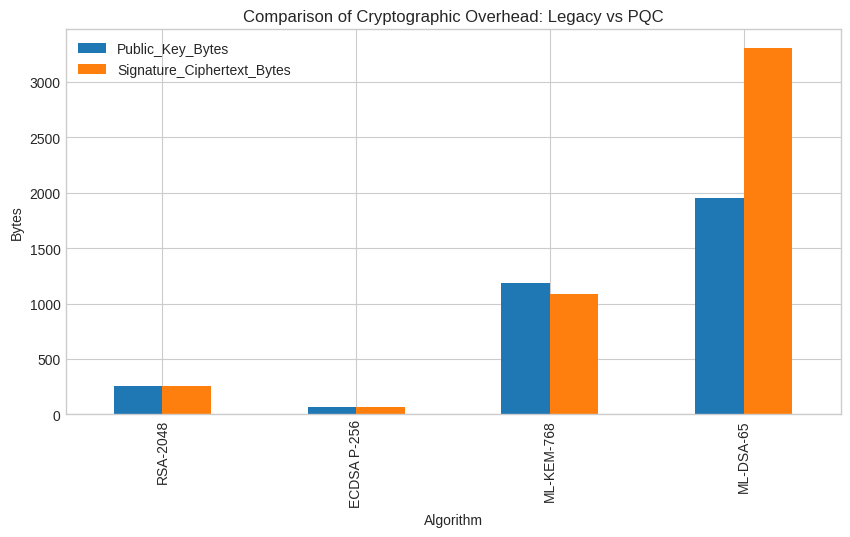

In [ ]:
# Data capturing the "Network Bandwidth Bottleneck"
data = {
    'Algorithm': ['RSA-2048', 'ECDSA P-256', 'ML-KEM-768', 'ML-DSA-65'],
    'Public_Key_Bytes': [256, 64, 1184, 1952],
    'Signature_Ciphertext_Bytes': [256, 64, 1088, 3309]
}
df_network = pd.DataFrame(data)
df_network['Total_Handshake_Load'] = df_network['Public_Key_Bytes'] + df_network['Signature_Ciphertext_Bytes']

# Visualize the overhead
df_network.plot(x='Algorithm', y=['Public_Key_Bytes', 'Signature_Ciphertext_Bytes'], kind='bar', figsize=(10, 5))
plt.title('Comparison of Cryptographic Overhead: Legacy vs PQC')
plt.ylabel('Bytes')
plt.savefig('/content/drive/MyDrive/Real_PQC_Empirical_Study/network_overhead.png')
plt.show()

In [ ]:
import glob

# Retrieve all CSVs from the study directory
all_files = glob.glob('/content/drive/MyDrive/Real_PQC_Empirical_Study/*.csv')
master_df = pd.concat((pd.read_csv(f) for f in all_files), ignore_index=True)

# Final Summary Table for Article
summary = master_df.groupby('Algorithm').mean()
print("=== FINAL EMPIRICAL SUMMARY TABLE ===")
display(summary)

# Trigger Visualizations for conceptual clarity
#
#

=== FINAL EMPIRICAL SUMMARY TABLE ===


,Mean_Latency_ms,Std_Dev_ms,P99_Latency_ms
Algorithm,,,
Kyber1024,0.076232,0.008791,0.109635
Kyber512,0.042085,0.006885,0.053838
Kyber768,0.058909,0.006314,0.069262
ML-KEM-1024,0.079836,0.010646,0.126303
ML-KEM-512,0.042557,0.019521,0.064373
ML-KEM-768,0.061073,0.007530,0.091944
